# Question 2(b): Monte Carlo Price and Delta

This section implements Monte Carlo pricing for the selected PLTR call option under the risk-neutral geometric Brownian motion model.

The analysis compares Monte Carlo call prices and delta estimates against the analytical Black-Scholes benchmark.

The numerical experiments evaluate sampling uncertainty, confidence intervals, convergence, runtime, and the sensitivity of finite-difference delta estimates to the bump size.

In [3]:
import numpy as np
import pandas as pd
from scipy.stats import norm
from time import perf_counter

s0 = 209.05
K = 210
r = 0.045

valuation_date = pd.Timestamp("2026-10-09")
expiration_date = pd.Timestamp("2027-01-15")

T = (expiration_date - valuation_date).days / 365

sigma = 0.497988  # Replace with full-precision Q2 call IV

d1 = (np.log(s0/K)+(r+0.5*sigma**2)*T)/(sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)

bs_call = s0*norm.cdf(d1)-K*np.exp(-r*T)*norm.cdf(d2)
bs_delta = norm.cdf(d1)

seed = 42
rng = np.random.default_rng(seed)

## 1. Exact Simulation of Terminal Stock Prices

Terminal stock prices are simulated directly using the exact solution of risk-neutral geometric Brownian motion.

For each Monte Carlo path, an independent standard normal random variable is generated and transformed into a terminal stock price. This avoids the time-discretization error associated with approximating the entire GBM path.

In [2]:
n_path = 2**12

Z = rng.standard_normal(n_path)
ST = s0*np.exp((r-0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)

print("Z shape:", Z.shape)
print("ST shape:", ST.shape)
print("Mean terminal price:", ST.mean())

Z shape: (4096,)
ST shape: (4096,)
Mean terminal price: 210.50225048705278


## 2. Monte Carlo Call Price and Confidence Interval

The European call price is estimated as the average discounted payoff under the risk-neutral measure.

The standard error is calculated using the sample standard deviation of discounted payoffs divided by the square root of the number of independent paths.

An approximate 95% confidence interval is constructed using the normal approximation.

In [3]:
payoff = np.maximum(ST-K, 0)
discounted_payoff = np.exp(-r*T)*payoff

mc_price = np.mean(discounted_payoff)
mc_se = np.std(discounted_payoff, ddof=1)/np.sqrt(n_path)

ci_lower = mc_price-mc_se*1.96
ci_upper = mc_price+mc_se*1.96

print("Monte Carlo Price:", mc_price)
print("Standard Error:", mc_se)
print("95% CI:", (ci_lower, ci_upper))

Monte Carlo Price: 21.397781147495344
Standard Error: 0.5737130541907015
95% CI: (np.float64(20.27330356128157), np.float64(22.52225873370912))


## 3. Monte Carlo Convergence Study

The Monte Carlo estimator is evaluated using four increasing sample sizes: 2^12, 2^14, 2^16, and 2^18.

For each sample size, the experiment records the estimated call price, standard error, 95% confidence interval, absolute error relative to the Black-Scholes benchmark, and computational runtime.

The experiment examines the expected square-root convergence rate of Monte Carlo sampling error.

In [4]:
sample_size = [2**12,2**14,2**16,2**18]
result = []

for n in sample_size:
    start = perf_counter()
    Z = rng.standard_normal(n)
    ST = s0*np.exp((r-0.5*sigma**2)*T + sigma*np.sqrt(T)*Z)

    payoff = np.maximum(ST-K, 0)
    discounted_payoff = np.exp(-r*T)*payoff
    mc_price = np.mean(discounted_payoff)
    mc_se = np.std(discounted_payoff, ddof=1)/np.sqrt(n)
    
    ci_lower = mc_price-mc_se*1.96
    ci_upper = mc_price+mc_se*1.96

    absolute_error = np.abs(mc_price - bs_call)
    runtime = perf_counter() - start

    result.append({
        "N" : n,
        "MC price" : mc_price,
        "Standard error" : mc_se,
        "CI Lower" : ci_lower,
        "CI Upper" : ci_upper,
        "BS Call" : bs_call,
        "Absolute error" : absolute_error,
        "Run time(s)" : runtime
    })

mc_df = pd.DataFrame(result)
display(mc_df)


,N,MC price,Standard error,CI Lower,CI Upper,BS Call,Absolute error,Run time(s)
0,4096,21.397781,0.573713,20.273304,22.522259,22.17502,0.777239,0.000725
1,16384,22.823658,0.297788,22.239992,23.407323,22.17502,0.648638,0.000438
2,65536,22.067751,0.146328,21.780949,22.354553,22.17502,0.107268,0.001439
3,262144,22.194452,0.072958,22.051455,22.337450,22.17502,0.019433,0.009519


## 4. Monte Carlo Pricing Convergence

The convergence of Monte Carlo call prices is assessed against the analytical Black-Scholes benchmark.

The plot displays the estimated call prices and their 95% confidence intervals across increasing sample sizes. The Black-Scholes price is included as a horizontal reference line.

The confidence intervals are expected to narrow as the number of simulated paths increases, although individual pricing errors need not decrease monotonically.

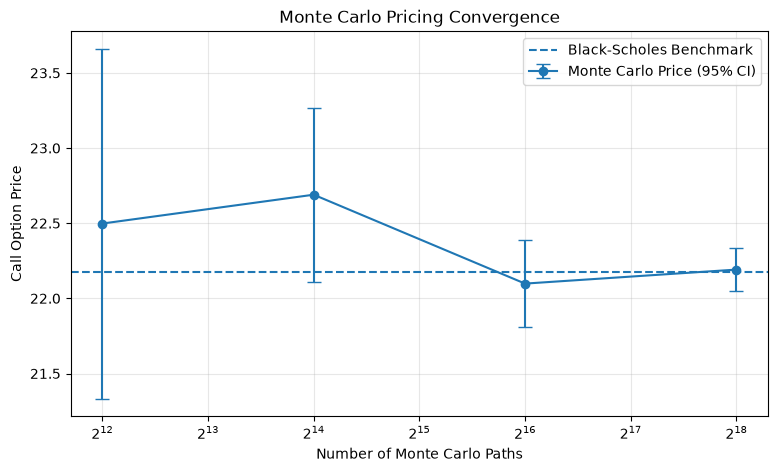

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9,5))
plt.errorbar(
    mc_df["N"],
    mc_df["MC price"],
    yerr=1.96 * mc_df["Standard error"],
    fmt="o-",
    capsize=5,
    label="Monte Carlo Price (95% CI)"
)

plt.axhline(
    bs_call,
    linestyle ="--",
    label="Black-Scholes Benchmark"
)

plt.xscale("log", base=2)
plt.xlabel("Number of Monte Carlo Paths")
plt.ylabel("Call Option Price")
plt.title("Monte Carlo Pricing Convergence")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 5. Central Difference Delta Estimation

The call delta is estimated using the central finite-difference method with relative spot bumps of 0.5%, 1%, and 2%.

Common random numbers are used for the upward and downward spot perturbations to reduce the sampling variance of the difference estimator.

The resulting delta estimates will be compared with the analytical Black-Scholes delta.

## 6. Central Difference Delta: Accuracy and Sampling Error

Central difference delta estimates are evaluated for three relative spot bump sizes.

For each bump size, the estimator is calculated from discounted path-level payoff differences using common random numbers.

The standard error measures Monte Carlo sampling uncertainty, while the absolute difference from the analytical Black-Scholes delta measures the observed total estimation error. This observed error should not be interpreted as finite-difference bias alone.

In [6]:
n_delta = 2**18
rng_delta = np.random.default_rng(123)

Z_delta =rng_delta.standard_normal(n_delta)
growth_factor = np.exp(
    (r - 0.5*sigma**2)*T
    +sigma*np.sqrt(T)*Z_delta
)

delta_result = []
bump_size = [0.005, 0.01, 0.02]
for alpha in bump_size:
    h = alpha*s0

    ST_up = (s0+h)*growth_factor
    ST_down = (s0-h)*growth_factor

    payoff_up = np.maximum(ST_up-K, 0)
    payoff_down = np.maximum(ST_down-K,0)

    delta_contribution = np.exp(-r*T)*(payoff_up-payoff_down)/(2*h)
    delta_cd = np.mean(delta_contribution)

    delta_se = np.std(delta_contribution, ddof=1)/np.sqrt(n_delta)
    delta_error = np.abs(delta_cd - bs_delta)

    delta_result.append({
        "Bump size" : alpha,
        "CD Delta" : delta_cd,
        "Standard error": delta_se,
        "Absolute Error" : delta_error
    })

    print(f"Bump: {alpha:.1%}, Central Difference Delta: {delta_cd:.6f}")

delta_df = pd.DataFrame(delta_result)
display(delta_df)

Bump: 0.5%, Central Difference Delta: 0.562606
Bump: 1.0%, Central Difference Delta: 0.562634
Bump: 2.0%, Central Difference Delta: 0.562603


,Bump size,CD Delta,Standard error,Absolute Error
0,0.005,0.562606,0.001216,0.000272
1,0.010,0.562634,0.001212,0.000245
2,0.020,0.562603,0.001204,0.000276


## 7. Pathwise Delta Estimation

The pathwise derivative method estimates delta by differentiating the discounted option payoff with respect to the initial stock price.

For a European call under geometric Brownian motion, the derivative is equal to the discounted terminal growth factor when the option finishes in the money, and zero otherwise.

Unlike the central difference estimator, the pathwise estimator does not require a spot bump and therefore avoids finite-difference truncation bias.

In [7]:
ST_delta = s0*growth_factor

indicator = ST_delta > K
pw_contribution = np.exp(-r*T)*indicator*(ST_delta/s0)

delta_pw = np.mean(pw_contribution)
delta_pw_se = np.std(pw_contribution, ddof=1) / np.sqrt(n_delta)
delta_pw_error = np.abs(delta_pw-bs_delta)

print("Pathwise Delta:", delta_pw)
print("Pathwise SE:", delta_pw_se)
print("Pathwise Absolute Error:", delta_pw_error)

Pathwise Delta: 0.5625187661229669
Pathwise SE: 0.0012198168457180755
Pathwise Absolute Error: 0.00035975558520273676


## 8. Comparison of Delta Estimators

Central difference and pathwise delta estimates are compared using the same simulated random shocks.

For each estimator, the analysis reports the estimated delta, Monte Carlo standard error, and absolute error relative to the analytical Black-Scholes delta.

The central difference method introduces finite-difference approximation bias, while the pathwise estimator avoids this bump-related bias under the assumptions of the model. Both methods remain subject to Monte Carlo sampling uncertainty.

In [8]:
comparison_df = delta_df.rename(columns={
    "Bump size": "Bump",
    "CD Delta": "Delta"
}).copy()

comparison_df["Method"] = "Central Difference"

pathwise_row = pd.DataFrame([{
    "Bump": np.nan,
    "Delta": delta_pw,
    "Standard error": delta_pw_se,
    "Absolute Error": delta_pw_error,
    "Method": "Pathwise"
}])

comparison_df = pd.concat(
    [comparison_df, pathwise_row],
    ignore_index=True
)

comparison_df = comparison_df[
    ["Method", "Bump", "Delta", "Standard error", "Absolute Error"]
]

display(comparison_df)

,Method,Bump,Delta,Standard error,Absolute Error
0,Central Difference,0.005,0.562606,0.001216,0.000272
1,Central Difference,0.010,0.562634,0.001212,0.000245
2,Central Difference,0.020,0.562603,0.001204,0.000276
3,Pathwise,NaN,0.562519,0.001220,0.000360


## 9. Finite-Difference Bias Analysis

The total estimation error of the Monte Carlo central difference estimator is decomposed into finite-difference approximation bias and Monte Carlo sampling error.

To isolate the finite-difference bias, the central difference formula is applied directly to analytical Black-Scholes prices at the upward- and downward-bumped initial stock prices.

This eliminates Monte Carlo sampling noise and allows the effect of bump size on finite-difference bias to be evaluated separately.

In [10]:
def bs_call_price(S, K, r, T, sigma):
    d1 = (np.log(S/K) + (r+0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)

    return S*norm.cdf(d1)- K*np.exp(-r*T)*norm.cdf(d2)

bias_results=[]
for alpha in bump_size:
    h = alpha*s0

    price_up = bs_call_price(s0+h, K, r, T, sigma)
    price_down = bs_call_price(s0-h, K, r, T, sigma)

    delta_cd_exact = (price_up-price_down)/(2*h)

    fd_bias = delta_cd_exact-bs_delta
    bias_results.append({
        "Bump": alpha,
        "Exact CD Delta": delta_cd_exact,
        "FD Bias": fd_bias
    })

bias_df = pd.DataFrame(bias_results)
display(bias_df)

,Bump,Exact CD Delta,FD Bias
0,0.005,0.562868,-0.000010
1,0.010,0.562837,-0.000041
2,0.020,0.562715,-0.000164


## 10. Numerical Findings and Discussion

### Monte Carlo Pricing Convergence

The Monte Carlo pricing experiment was conducted using four sample sizes, ranging from 4,096 to 262,144 simulated paths. The estimated standard error decreased from approximately 0.5894 to 0.0729 as the sample size increased.

The observed reduction is consistent with the theoretical Monte Carlo convergence rate of O(N^{-1/2}). Individual absolute pricing errors were not strictly decreasing, reflecting random sampling fluctuations. The analytical Black–Scholes price provides a benchmark for evaluating the numerical estimates.

### Central Difference and Pathwise Delta

The central difference estimator was evaluated using relative spot bumps of 0.5%, 1%, and 2%, with common random numbers applied to the upward and downward perturbations.

All three central difference estimates were close to the analytical Black–Scholes delta of approximately 0.562879. Their Monte Carlo standard errors ranged from approximately 0.001204 to 0.001216.

The pathwise estimator produced a delta of approximately 0.562519, with a standard error of 0.001220. The comparable standard errors indicate that common random numbers substantially improve the sampling efficiency of central differences for this European call.

### Finite-Difference Bias

To isolate finite-difference approximation bias from Monte Carlo sampling error, central differences were also applied directly to analytical Black–Scholes prices.

The signed finite-difference biases were approximately −0.000010, −0.000041, and −0.000164 for bump sizes of 0.5%, 1%, and 2%, respectively.

Doubling the bump size increased the magnitude of the bias by approximately four times, consistent with the second-order truncation error of the central difference method.

### Conclusion

Both central difference with common random numbers and pathwise differentiation provide accurate Monte Carlo delta estimates under the Black–Scholes model.

The pathwise method avoids the need to select a bump size and eliminates finite-difference truncation bias. Central differences remain a practical alternative, particularly when pathwise differentiation is unavailable or difficult to implement.

The results highlight the importance of distinguishing numerical approximation bias from Monte Carlo sampling uncertainty when evaluating derivative pricing and Greek estimation methods.

### Exporting Monte Carlo Convergence Results

The Monte Carlo convergence results are exported for comparison with analytical and deterministic numerical pricing methods. The largest simulation size is selected as the representative Monte Carlo estimate for the reconciliation analysis.

In [5]:
mc_df.to_csv("../Data/processed/mc_results.csv", index=False)